# E003 — Transaction Velocity Feature Engineering (CatBoost GPU)

**Competition:** Bank card fraud detection  
**Goal:** Test whether cards being used repeatedly within short periods improve fraud ranking.  
**Model:** `CatBoostClassifier(task_type="GPU", devices="0")`  
**Primary metric:** ROC AUC, evaluated on the **same three chronological folds** as E001 and E002.

### Starting benchmarks

| Experiment | Feature group | Mean CV ROC AUC |
|:--|:--|--:|
| **E001-B** | Original 14 columns | **0.87424** |
| **E002-B** | Original + customer spending features | **0.89328** |

**Research hypothesis:** Rapid repeat transactions on one card may indicate an abnormal burst of activity. However, repeat purchases can also be entirely legitimate, so we must measure their value through validation.

### Experimental design

| ID | Predictors | Question |
|:--|:--|:--|
| **E001-repeat** | Original 14 features | Does the control still reproduce our baseline? |
| **E003-A** | Original + time since previous transaction | Does the gap since last use help? |
| **E003-B** | E003-A + number of earlier transactions in 5 min and 1 hour | Does rapid frequency help? |
| **E003-C** | E003-B + number in 24 hours and amount spent in 1 hour | Does longer-term intensity help? |

**Crucial rule:** E003 tests *velocity independently* of E002's spending-statistics group. We'll test combinations in E006, not here.

## 1 — Imports and load competition data

`pd.read_csv()` loads each CSV. The files use **different timestamp formats**, so we parse them explicitly and verify training transactions occur before the test period.

The path search supports running the notebook from the repository root or its `notebooks/` directory.

In [1]:
from pathlib import Path
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from catboost import CatBoostClassifier
from sklearn.metrics import roc_auc_score

working_dir = Path.cwd()
possible_data_dirs = [working_dir / "data", working_dir.parent / "data"]
data_dir = next(
    (folder for folder in possible_data_dirs
     if (folder / "train.csv").exists() and (folder / "test.csv").exists()),
    None,
)
if data_dir is None:
    raise FileNotFoundError("Place train.csv and test.csv in the repository's data/ folder.")

project_root = data_dir.parent
train_raw = pd.read_csv(data_dir / "train.csv")
test_raw = pd.read_csv(data_dir / "test.csv")

train_raw["timestamp"] = pd.to_datetime(
    train_raw["timestamp"], format="%Y-%m-%d %H:%M:%S"
)
test_raw["timestamp"] = pd.to_datetime(
    test_raw["timestamp"], format="%m/%d/%Y %H:%M"
)
train_raw = train_raw.sort_values("timestamp", kind="stable").reset_index(drop=True)

assert "is_fraud" in train_raw.columns
assert "is_fraud" not in test_raw.columns
assert train_raw["transaction_id"].is_unique
assert test_raw["transaction_id"].is_unique
assert train_raw["timestamp"].notna().all() and test_raw["timestamp"].notna().all()
assert train_raw["timestamp"].max() < test_raw["timestamp"].min()

print("Project:", project_root)
print("Training rows:", len(train_raw), "| Test rows:", len(test_raw))
print("Train:", train_raw["timestamp"].min(), "to", train_raw["timestamp"].max())
print("Test: ", test_raw["timestamp"].min(), "to", test_raw["timestamp"].max())

Project: c:\Users\acer\Desktop\Dabpe\DADS\Fraud-Detection-CatBoost
Training rows: 60197 | Test rows: 39803
Train: 2026-01-01 00:07:15 to 2026-02-05 23:59:19
Test:  2026-02-06 00:07:00 to 2026-03-02 00:36:00


## 2 — Engineer *past-only* transaction-velocity features

For every transaction, we look at **earlier transactions made by the same card**.

| Feature | Meaning |
|:--|:--|
| `minutes_since_previous_txn` | Minutes since the card's most recent **earlier** transaction; `-1` if none exists |
| `card_txn_5min` | Count of earlier transactions by that card in the preceding **5 minutes** |
| `card_txn_1h` | Count of earlier transactions by that card in the preceding **1 hour** |
| `card_txn_24h` | Count of earlier transactions by that card in the preceding **24 hours** |
| `card_amount_sum_1h` | Total USD spent by that card in the preceding **1 hour**; excludes current amount |

**Important:** We use a strict timestamp comparison: earlier means `previous_timestamp < current_timestamp`. If two transactions share exactly the same timestamp, neither is treated as earlier than the other. The 5-minute window includes transactions exactly five minutes before the current timestamp, but excludes any transaction at the current timestamp.

We compute over `train + test` **without using any fraud labels**. Unlike E002's full-period spending aggregates, these velocity features also use **only past events**, so future transactions do not change a transaction's features.

### How `numpy.searchsorted()` helps

For sorted timestamps, `np.searchsorted(times, current_time, side="left")` finds the position of the first event at the current timestamp. That position is the number of *strictly earlier* events. We subtract the position of the first event inside a lookback window to get the event count.

This is faster and easier to verify on repeated timestamps than recomputing a full DataFrame filter for every transaction.

In [2]:
VELOCITY_FEATURES = [
    "minutes_since_previous_txn",
    "card_txn_5min",
    "card_txn_1h",
    "card_txn_24h",
    "card_amount_sum_1h",
]


def build_velocity_features(transaction_rows: pd.DataFrame) -> pd.DataFrame:
    """Return one transaction_id + past-only velocity features per input row.

    Required columns: transaction_id, card_id, timestamp (datetime64), amount.
    Never reads is_fraud or any future transaction for a feature at time t.
    """
    required = ["transaction_id", "card_id", "timestamp", "amount"]
    if not set(required).issubset(transaction_rows.columns):
        raise ValueError(f"Missing columns from {required}")

    events = transaction_rows[required].copy()
    if not events["transaction_id"].is_unique:
        raise ValueError("transaction_id must be unique")
    if events["timestamp"].isna().any() or events["card_id"].isna().any():
        raise ValueError("card_id and timestamp must not be missing")
    if events["amount"].isna().any():
        raise ValueError("amount must not be missing")

    # Stable sorting makes events for the same card chronological.
    events = events.sort_values(["card_id", "timestamp"], kind="stable").reset_index(drop=True)
    row_count = len(events)

    gap_minutes = np.full(row_count, -1.0, dtype=np.float64)
    count_5min = np.zeros(row_count, dtype=np.int32)
    count_1h = np.zeros(row_count, dtype=np.int32)
    count_24h = np.zeros(row_count, dtype=np.int32)
    amount_sum_1h = np.zeros(row_count, dtype=np.float64)

    minute_ns = 60 * 1_000_000_000
    hour_ns = 60 * minute_ns
    day_ns = 24 * hour_ns

    # Each group contains exactly one card. The indices are positions in events.
    for card_id, positions in events.groupby("card_id", sort=False).indices.items():
        card_rows = events.iloc[positions]
        times_ns = card_rows["timestamp"].to_numpy(dtype="datetime64[ns]").astype("int64")
        amounts = card_rows["amount"].to_numpy(dtype=np.float64)

        # Index of first event at current time; excludes current and tied events.
        prior_end = np.searchsorted(times_ns, times_ns, side="left")
        has_prior = prior_end > 0

        local_gaps = np.full(len(times_ns), -1.0, dtype=np.float64)
        previous_positions = prior_end[has_prior] - 1
        local_gaps[has_prior] = (
            times_ns[has_prior] - times_ns[previous_positions]
        ) / minute_ns
        gap_minutes[positions] = local_gaps

        window_5min = np.searchsorted(times_ns, times_ns - 5 * minute_ns, side="left")
        window_1h = np.searchsorted(times_ns, times_ns - hour_ns, side="left")
        window_24h = np.searchsorted(times_ns, times_ns - day_ns, side="left")

        count_5min[positions] = prior_end - window_5min
        count_1h[positions] = prior_end - window_1h
        count_24h[positions] = prior_end - window_24h

        # Prefix sums allow O(1) calculation of spending in any time window.
        cumulative_amount = np.r_[0.0, np.cumsum(amounts)]
        amount_sum_1h[positions] = (
            cumulative_amount[prior_end] - cumulative_amount[window_1h]
        )

    events["minutes_since_previous_txn"] = gap_minutes
    events["card_txn_5min"] = count_5min
    events["card_txn_1h"] = count_1h
    events["card_txn_24h"] = count_24h
    events["card_amount_sum_1h"] = np.maximum(amount_sum_1h, 0.0)

    # Restore input transaction order using a one-to-one key.
    return transaction_rows[["transaction_id"]].merge(
        events[["transaction_id"] + VELOCITY_FEATURES],
        on="transaction_id", how="left", validate="one_to_one", sort=False
    )


# Combine only transaction covariates. Labels never enter the feature function.
required_cols = ["transaction_id", "card_id", "timestamp", "amount"]
all_unlabeled_transactions = pd.concat(
    [train_raw[required_cols], test_raw[required_cols]],
    ignore_index=True,
)
assert all_unlabeled_transactions["transaction_id"].is_unique

velocity_table = build_velocity_features(all_unlabeled_transactions)
train_features = train_raw.merge(
    velocity_table, on="transaction_id", how="left", validate="one_to_one", sort=False
)
test_features = test_raw.merge(
    velocity_table, on="transaction_id", how="left", validate="one_to_one", sort=False
)

assert train_features["transaction_id"].equals(train_raw["transaction_id"])
assert test_features["transaction_id"].equals(test_raw["transaction_id"])
assert train_features[VELOCITY_FEATURES].notna().all().all()
assert test_features[VELOCITY_FEATURES].notna().all().all()
assert (train_features[["card_txn_5min", "card_txn_1h", "card_txn_24h"]] >= 0).all().all()
assert (train_features["card_txn_5min"] <= train_features["card_txn_1h"]).all()
assert (train_features["card_txn_1h"] <= train_features["card_txn_24h"]).all()

print("Velocity features created:", VELOCITY_FEATURES)
print("Train features:", train_features.shape, "| Test features:", test_features.shape)
display(train_features[["transaction_id", "timestamp", "card_id", "amount"] + VELOCITY_FEATURES].head(8))

Velocity features created: ['minutes_since_previous_txn', 'card_txn_5min', 'card_txn_1h', 'card_txn_24h', 'card_amount_sum_1h']
Train features: (60197, 25) | Test features: (39803, 24)


,transaction_id,timestamp,card_id,amount,minutes_since_previous_txn,card_txn_5min,card_txn_1h,card_txn_24h,card_amount_sum_1h
0,TXN_000001,2026-01-01 00:07:15,C03949,171.70,-1.0,0,0,0,0.0
1,TXN_000002,2026-01-01 00:34:05,C02996,248.09,-1.0,0,0,0,0.0
2,TXN_000003,2026-01-01 01:00:23,C06754,305.51,-1.0,0,0,0,0.0
3,TXN_000004,2026-01-01 01:05:07,C03321,7.47,-1.0,0,0,0,0.0
4,TXN_000005,2026-01-01 01:08:56,C00958,18.58,-1.0,0,0,0,0.0
5,TXN_000006,2026-01-01 01:14:21,C00186,20.64,-1.0,0,0,0,0.0
6,TXN_000007,2026-01-01 01:25:30,C00579,85.35,-1.0,0,0,0,0.0
7,TXN_000008,2026-01-01 01:34:05,C05199,15.95,-1.0,0,0,0,0.0


## 3 — Unit test: verify the time windows with a hand-calculated example

Consider card A at 10:00, 10:02, 10:03, and 10:04, then another transaction **also at 10:04**. Both 10:04 transactions should see three earlier transactions in the preceding 5 minutes, and previous-1h spending of **$20 + $30 + $500 = $550**. A different card B should have zero history.

`assert` statements stop execution immediately if any expected value is wrong.

In [3]:
small_example = pd.DataFrame({
    "transaction_id": ["a1", "a2", "a3", "a4", "a5", "b1"],
    "card_id": ["A", "A", "A", "A", "A", "B"],
    "timestamp": pd.to_datetime([
        "2026-01-01 10:00:00", "2026-01-01 10:02:00",
        "2026-01-01 10:03:00", "2026-01-01 10:04:00",
        "2026-01-01 10:04:00", "2026-01-01 10:04:00",
    ]),
    "amount": [20.0, 30.0, 500.0, 800.0, 900.0, 10.0],
})
check = build_velocity_features(small_example).set_index("transaction_id")
assert check.loc["a1", "minutes_since_previous_txn"] == -1.0
assert check.loc["a2", "minutes_since_previous_txn"] == 2.0
assert check.loc["a4", "minutes_since_previous_txn"] == 1.0
assert check.loc["a4", "card_txn_5min"] == 3
assert check.loc["a5", "card_txn_5min"] == 3  # same-time events excluded
assert np.isclose(check.loc["a4", "card_amount_sum_1h"], 550.0)
assert np.isclose(check.loc["a5", "card_amount_sum_1h"], 550.0)
assert check.loc["b1", "card_txn_5min"] == 0  # another card has no history

print("PASS — Counts, timing, spending, and tied timestamps are handled correctly.")
display(small_example.merge(check.reset_index(), on="transaction_id"))

PASS — Counts, timing, spending, and tied timestamps are handled correctly.


,transaction_id,card_id,timestamp,amount,minutes_since_previous_txn,card_txn_5min,card_txn_1h,card_txn_24h,card_amount_sum_1h
0,a1,A,2026-01-01 10:00:00,20.0,-1.0,0,0,0,0.0
1,a2,A,2026-01-01 10:02:00,30.0,2.0,1,1,1,20.0
2,a3,A,2026-01-01 10:03:00,500.0,1.0,2,2,2,50.0
3,a4,A,2026-01-01 10:04:00,800.0,1.0,3,3,3,550.0
4,a5,A,2026-01-01 10:04:00,900.0,1.0,3,3,3,550.0
5,b1,B,2026-01-01 10:04:00,10.0,-1.0,0,0,0,0.0


## 4 — Leakage check: do future transactions change earlier features?

We calculate velocity twice:

1. From the entire available **unlabeled** history, including future transactions.
2. From history **before Jan 19 only**.

If our implementation is genuinely past-only, the velocity features for pre-Jan-19 transactions will match exactly in both cases. This also checks the first CV fold's training history.

In [4]:
first_fold_start = pd.Timestamp("2026-01-19")
early_events = all_unlabeled_transactions.loc[
    all_unlabeled_transactions["timestamp"] < first_fold_start
].copy()
early_velocity = build_velocity_features(early_events).set_index("transaction_id")
full_early_velocity = velocity_table.set_index("transaction_id").loc[early_velocity.index]

pd.testing.assert_frame_equal(
    early_velocity[VELOCITY_FEATURES],
    full_early_velocity[VELOCITY_FEATURES],
    check_dtype=False, rtol=1e-10, atol=1e-8,
)
print("PASS — Future rows do not change past-only velocity features.")
print("Checked transactions:", len(early_events))

PASS — Future rows do not change past-only velocity features.
Checked transactions: 29618


## 5 — Explore how frequently cards are used within short periods

Let's inspect the *distribution* of the engineered features **before evaluating the model**.

- Many zero counts are possible because card activity is often sparse.
- Large counts can indicate bursts or just normal repeated activity.
- `minutes_since_previous_txn == -1` means the card has no previous transaction in our observed dataset; it is not a real negative time gap.

The plots describe behavior, **not evidence that a transaction is fraudulent**. E003 cross-validation provides that evidence.

,feature,min,median,p95,max,share_positive
0,minutes_since_previous_txn,-1.0,1546.517,14389.99,49123.067,0.889
1,card_txn_5min,0.0,0.000,0.00,3.000,0.014
2,card_txn_1h,0.0,0.000,1.00,7.000,0.077
3,card_txn_24h,0.0,0.000,3.00,11.000,0.362
4,card_amount_sum_1h,0.0,0.000,22.40,6857.690,0.077


Share of transactions with at least one earlier transaction in each window:
  card_txn_5min    : 1.42%
  card_txn_1h      : 7.66%
  card_txn_24h     : 36.24%


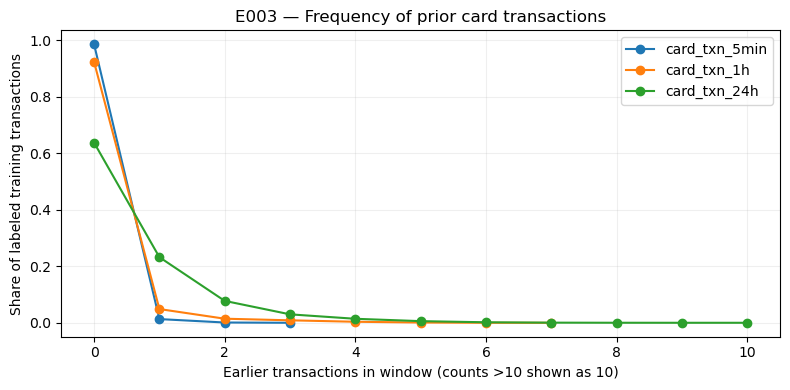

In [5]:
velocity_overview = pd.DataFrame({
    "feature": VELOCITY_FEATURES,
    "min": [train_features[column].min() for column in VELOCITY_FEATURES],
    "median": [train_features[column].median() for column in VELOCITY_FEATURES],
    "p95": [train_features[column].quantile(.95) for column in VELOCITY_FEATURES],
    "max": [train_features[column].max() for column in VELOCITY_FEATURES],
    "share_positive": [
        (train_features[column] > 0).mean() for column in VELOCITY_FEATURES
    ],
})
display(velocity_overview.round(3))

count_columns = ["card_txn_5min", "card_txn_1h", "card_txn_24h"]
print("Share of transactions with at least one earlier transaction in each window:")
for column in count_columns:
    print(f"  {column:17s}: {(train_features[column] >= 1).mean():.2%}")

fig, ax = plt.subplots(figsize=(8, 4))
plot_data = train_features[count_columns].clip(upper=10)
for column in count_columns:
    rates = plot_data[column].value_counts(normalize=True).sort_index()
    ax.plot(rates.index, rates.values, marker="o", label=column)
ax.set(xlabel="Earlier transactions in window (counts >10 shown as 10)",
       ylabel="Share of labeled training transactions",
       title="E003 — Frequency of prior card transactions")
ax.legend()
ax.grid(alpha=.2)
plt.tight_layout()
plt.show()

## 6 — Define the controlled feature sets and three chronological folds

We intentionally **do not include any E002 features** here, so we can isolate the incremental predictive value of transaction velocity.

All models use the same original columns, preprocessing, chronological CV windows, and GPU hyperparameters as our E001/E002 notebooks.

The baseline excludes `transaction_id`, `timestamp`, `card_holder`, `merchant_name`, `ip_address`, and the target from predictors. Timestamp remains available for creating the time splits and features.

In [6]:
excluded_columns = {
    "transaction_id", "timestamp", "card_holder", "merchant_name",
    "ip_address", "is_fraud",
}
original_features = [
    column for column in train_raw.columns if column not in excluded_columns
]
assert len(original_features) == 14, original_features

feature_sets = {
    "E001-repeat": original_features,
    "E003-A": original_features + ["minutes_since_previous_txn"],
    "E003-B": original_features + [
        "minutes_since_previous_txn", "card_txn_5min", "card_txn_1h",
    ],
    "E003-C": original_features + VELOCITY_FEATURES,
}

cat_features = train_raw[original_features].select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()

time_folds = [
    ("2026-01-19", "2026-01-25"),
    ("2026-01-25", "2026-01-31"),
    ("2026-01-31", "2026-02-06"),
]

for experiment_name, columns in feature_sets.items():
    assert len(columns) == len(set(columns))
    print(f"{experiment_name:12s}: {len(columns)} features")
print("Categorical predictors:", cat_features)

fold_checks = []
for fold_number, (start, end) in enumerate(time_folds, start=1):
    start_date, end_date = pd.Timestamp(start), pd.Timestamp(end)
    train_mask = train_features["timestamp"] < start_date
    valid_mask = (
        (train_features["timestamp"] >= start_date)
        & (train_features["timestamp"] < end_date)
    )
    y_fold_train = train_features.loc[train_mask, "is_fraud"]
    y_fold_valid = train_features.loc[valid_mask, "is_fraud"]
    assert y_fold_train.nunique() == 2
    assert y_fold_valid.nunique() == 2
    assert train_features.loc[train_mask, "timestamp"].max() < start_date
    fold_checks.append({
        "fold": fold_number, "train_rows": len(y_fold_train),
        "train_frauds": int(y_fold_train.sum()), "valid_rows": len(y_fold_valid),
        "valid_frauds": int(y_fold_valid.sum()),
        "valid_start": start, "valid_end_exclusive": end,
    })
display(pd.DataFrame(fold_checks))

E001-repeat : 14 features
E003-A      : 15 features
E003-B      : 17 features
E003-C      : 19 features
Categorical predictors: ['card_id', 'customer_home_country', 'merchant_id', 'merchant_category', 'merchant_country', 'channel', 'device_id', 'ip_country']


,fold,train_rows,train_frauds,valid_rows,valid_frauds,valid_start,valid_end_exclusive
0,1,29618,409,10336,140,2026-01-19,2026-01-25
1,2,39954,549,10263,94,2026-01-25,2026-01-31
2,3,50217,643,9980,156,2026-01-31,2026-02-06


## 7 — Train CatBoost on the GPU (12 separate fits)

`CatBoostClassifier` trains gradient-boosted decision trees. These parameters are **held constant** to compare feature groups fairly:

| Parameter | Value | Why |
|:--|:--|:--|
| `task_type="GPU"`, `devices="0"` | GPU 0 | Use NVIDIA RTX 3070 |
| `loss_function="Logloss"` | Binary cross-entropy | Training cost function |
| `eval_metric="AUC"` | ROC AUC | Competition ranking metric |
| `iterations=600`, `depth=6` | Fixed | Control capacity |
| `learning_rate=0.05`, `l2_leaf_reg=3.0` | Fixed | Control boosting step and leaf regularization |
| `early_stopping_rounds=70` | Fixed | Stop when monitored AUC doesn't improve |

Each CV fold trains a **fresh model**. We use `predict_proba()[:, 1]` to obtain the probability of class 1 (fraud), then compute `roc_auc_score()` on the validation labels.

**GPU information message:** CatBoost can report that AUC is not implemented for GPU and uses `metric_period=5`. This is an informational metric-calculation behavior; training still uses GPU and sklearn's final ROC AUC calculation is valid.

**Model-selection caveat:** The same validation window controls early stopping and reports performance, so these are **development scores**, not a completely independent final-test estimate.

In [7]:
EXPERIMENTS_TO_RUN = ["E001-repeat", "E003-A", "E003-B", "E003-C"]

model_parameters = dict(
    iterations=600,
    depth=6,
    learning_rate=0.05,
    l2_leaf_reg=3.0,
    loss_function="Logloss",
    eval_metric="AUC",
    task_type="GPU",
    devices="0",
    random_seed=42,
    verbose=False,
    allow_writing_files=False,
)

results = []
importance_records = []

for experiment_name in EXPERIMENTS_TO_RUN:
    selected_columns = feature_sets[experiment_name]
    print(f"\n===== {experiment_name}: {len(selected_columns)} features =====")

    for fold_number, (start, end) in enumerate(time_folds, start=1):
        start_date, end_date = pd.Timestamp(start), pd.Timestamp(end)
        train_mask = train_features["timestamp"] < start_date
        valid_mask = (
            (train_features["timestamp"] >= start_date)
            & (train_features["timestamp"] < end_date)
        )

        X_fold_train = train_features.loc[train_mask, selected_columns].copy()
        X_fold_valid = train_features.loc[valid_mask, selected_columns].copy()
        y_fold_train = train_features.loc[train_mask, "is_fraud"]
        y_fold_valid = train_features.loc[valid_mask, "is_fraud"]

        # Replicate E001/E002 preprocessing exactly.
        for frame in (X_fold_train, X_fold_valid):
            frame["card_present"] = frame["card_present"].astype("int8")
            frame[cat_features] = frame[cat_features].fillna("__MISSING__").astype(str)
        assert X_fold_train.columns.tolist() == X_fold_valid.columns.tolist()
        assert X_fold_train[cat_features].notna().all().all()
        assert X_fold_train.select_dtypes(include=["number"]).notna().all().all()

        model = CatBoostClassifier(**model_parameters)
        start_time = perf_counter()
        model.fit(
            X_fold_train, y_fold_train,
            cat_features=cat_features,
            eval_set=(X_fold_valid, y_fold_valid),
            early_stopping_rounds=70,
            use_best_model=True,
        )
        elapsed_seconds = perf_counter() - start_time
        fraud_probabilities = model.predict_proba(X_fold_valid)[:, 1]
        fold_auc = roc_auc_score(y_fold_valid, fraud_probabilities)

        results.append({
            "experiment_id": experiment_name,
            "fold": fold_number,
            "train_rows": len(X_fold_train),
            "valid_rows": len(X_fold_valid),
            "valid_frauds": int(y_fold_valid.sum()),
            "roc_auc": fold_auc,
            "best_iteration": model.best_iteration_,
            "train_seconds": round(elapsed_seconds, 2),
        })

        # Save importances for EACH fold, not just the very last fitted model.
        for feature_name, importance in zip(
            selected_columns, model.get_feature_importance()
        ):
            importance_records.append({
                "experiment_id": experiment_name,
                "fold": fold_number,
                "feature": feature_name,
                "importance": float(importance),
            })

        print(
            f"Fold {fold_number}: ROC AUC={fold_auc:.5f}, "
            f"best_iteration={model.best_iteration_}, "
            f"train_seconds={elapsed_seconds:.1f}"
        )

results_df = pd.DataFrame(results)
importance_all_folds = pd.DataFrame(importance_records)
display(results_df)


===== E001-repeat: 14 features =====


Default metric period is 5 because AUC is/are not implemented for GPU


Fold 1: ROC AUC=0.88680, best_iteration=90, train_seconds=9.5


Default metric period is 5 because AUC is/are not implemented for GPU


Fold 2: ROC AUC=0.83746, best_iteration=16, train_seconds=5.1


Default metric period is 5 because AUC is/are not implemented for GPU


... (16 outputs left out)

Fold 2: ROC AUC=0.87528, best_iteration=211, train_seconds=15.9


Default metric period is 5 because AUC is/are not implemented for GPU


Fold 3: ROC AUC=0.94185, best_iteration=172, train_seconds=6.8


,experiment_id,fold,train_rows,valid_rows,valid_frauds,roc_auc,best_iteration,train_seconds
0,E001-repeat,1,29618,10336,140,0.886804,90,9.50
1,E001-repeat,2,39954,10263,94,0.837461,16,5.12
2,E001-repeat,3,50217,9980,156,0.898440,14,2.63
3,E003-A,1,29618,10336,140,0.909719,119,10.77
4,E003-A,2,39954,10263,94,0.874888,126,11.41
5,E003-A,3,50217,9980,156,0.942907,14,2.77
6,E003-B,1,29618,10336,140,0.906884,15,5.26
7,E003-B,2,39954,10263,94,0.875520,8,4.92
8,E003-B,3,50217,9980,156,0.941835,12,2.70
9,E003-C,1,29618,10336,140,0.895261,57,7.38


## 8 — Compare E003 against the **repeated E001 baseline**

We compute the unweighted mean ROC AUC and sample standard deviation across the same three folds used previously. We also compare each fold independently because a gain in one period could conceal a loss in another.

**Note:** E002-B's 0.89328 is our best spending-model benchmark, but it's not part of the E003 feature set. We will combine groups only in E006.

,experiment_id,mean_roc_auc,std_roc_auc,min_fold_auc,max_fold_auc,mean_best_iteration,delta_vs_e001
0,E001-repeat,0.87424,0.03237,0.83746,0.89844,40.00000,0.00000
1,E003-A,0.90917,0.03401,0.87489,0.94291,86.33333,0.03494
2,E003-B,0.90808,0.03317,0.87552,0.94184,11.66667,0.03384
3,E003-C,0.90413,0.03416,0.87528,0.94185,146.66667,0.02990


experiment_id,E001-repeat,E003-A,E003-B,E003-C
fold,,,,
1,0.88680,0.90972,0.90688,0.89526
2,0.83746,0.87489,0.87552,0.87528
3,0.89844,0.94291,0.94184,0.94185


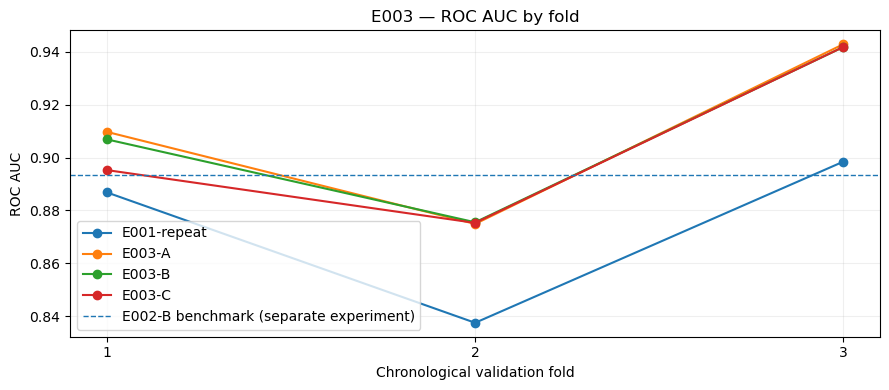

In [8]:
summary_df = (
    results_df.groupby("experiment_id", sort=False)
    .agg(
        mean_roc_auc=("roc_auc", "mean"),
        std_roc_auc=("roc_auc", "std"),
        min_fold_auc=("roc_auc", "min"),
        max_fold_auc=("roc_auc", "max"),
        mean_best_iteration=("best_iteration", "mean"),
    )
    .reset_index()
)

baseline_row = summary_df.loc[
    summary_df["experiment_id"] == "E001-repeat", "mean_roc_auc"
]
if len(baseline_row) == 1:
    baseline_auc = float(baseline_row.iloc[0])
    summary_df["delta_vs_e001"] = summary_df["mean_roc_auc"] - baseline_auc
else:
    print("Warning: baseline not rerun. Add E001-repeat for controlled comparisons.")

display(summary_df.round(5))

fold_auc_table = results_df.pivot(
    index="fold", columns="experiment_id", values="roc_auc"
)
display(fold_auc_table.round(5))

fig, ax = plt.subplots(figsize=(9, 4))
for experiment_name in fold_auc_table.columns:
    ax.plot(fold_auc_table.index, fold_auc_table[experiment_name],
            marker="o", label=experiment_name)
ax.axhline(0.89328, linestyle="--", linewidth=1,
           label="E002-B benchmark (separate experiment)")
ax.set(xlabel="Chronological validation fold", ylabel="ROC AUC",
       title="E003 — ROC AUC by fold", xticks=[1, 2, 3])
ax.legend()
ax.grid(alpha=.2)
plt.tight_layout()
plt.show()

## 9 — Feature importance across chronological folds

`model.get_feature_importance()` measures how much the fitted CatBoost model uses features (default importance type for classification). It is **not** a causal explanation and can distribute importance unpredictably across correlated features.

Because importance may vary across periods, we'll average it over the three folds **within each experiment**. Watch whether `card_txn_5min`, `card_txn_1h`, or the time gap receive consistent importance. A zero score alone is not a reason to remove a feature.

In [9]:
if not importance_all_folds.empty:
    for experiment_name in ["E003-A", "E003-B", "E003-C"]:
        subset = importance_all_folds.loc[
            importance_all_folds["experiment_id"] == experiment_name
        ]
        importance_summary = (
            subset.groupby("feature", as_index=False)
            .agg(mean_importance=("importance", "mean"),
                 min_importance=("importance", "min"),
                 max_importance=("importance", "max"))
            .sort_values("mean_importance", ascending=False)
        )
        print("\n", experiment_name, "— mean feature importance across folds")
        display(importance_summary.head(20).round(3))


 E003-A — mean feature importance across folds


,feature,mean_importance,min_importance,max_importance
1,amount,23.805,11.287,30.213
11,merchant_category,20.453,12.089,32.384
14,minutes_since_previous_txn,14.848,11.745,18.543
13,merchant_id,13.400,11.475,15.921
10,is_foreign_merchant,11.526,7.957,16.672
2,card_id,5.253,0.000,8.444
9,is_foreign_ip,2.940,2.699,3.071
4,channel,2.143,1.991,2.315
12,merchant_country,1.657,1.105,2.283
0,account_age_days,1.615,0.203,2.355



 E003-B — mean feature importance across folds


,feature,mean_importance,min_importance,max_importance
13,merchant_category,26.620,23.279,31.081
16,minutes_since_previous_txn,15.166,12.272,20.587
1,amount,14.789,5.138,28.733
12,is_foreign_merchant,14.011,10.556,19.286
15,merchant_id,12.068,11.628,12.794
6,channel,5.635,3.579,7.785
4,card_txn_1h,4.060,1.623,8.420
11,is_foreign_ip,2.872,2.589,3.040
0,account_age_days,2.083,0.486,2.910
14,merchant_country,1.745,1.105,2.516



 E003-C — mean feature importance across folds


,feature,mean_importance,min_importance,max_importance
1,amount,28.783,20.485,37.825
15,merchant_category,13.962,10.377,15.965
17,merchant_id,12.904,12.318,13.423
14,is_foreign_merchant,8.865,6.470,11.461
18,minutes_since_previous_txn,7.256,6.711,7.817
3,card_id,6.723,6.025,7.159
2,card_amount_sum_1h,6.249,5.726,7.018
5,card_txn_1h,2.727,1.373,4.757
8,channel,2.683,1.509,4.009
13,is_foreign_ip,2.555,1.738,3.187


## 10 — Export experiment results

Store compact CSV summaries in `experiments/` for version control. We do not save GPU model binaries or copy large feature datasets by default.

In [10]:
experiments_dir = project_root / "experiments"
experiments_dir.mkdir(parents=True, exist_ok=True)

fold_results_path = experiments_dir / "E003_cv_results.csv"
summary_path = experiments_dir / "E003_summary.csv"
importance_path = experiments_dir / "E003_feature_importance.csv"

results_df.to_csv(fold_results_path, index=False)
summary_df.to_csv(summary_path, index=False)
importance_all_folds.to_csv(importance_path, index=False)

print("Saved:", fold_results_path)
print("Saved:", summary_path)
print("Saved:", importance_path)

Saved: c:\Users\acer\Desktop\Dabpe\DADS\Fraud-Detection-CatBoost\experiments\E003_cv_results.csv
Saved: c:\Users\acer\Desktop\Dabpe\DADS\Fraud-Detection-CatBoost\experiments\E003_summary.csv
Saved: c:\Users\acer\Desktop\Dabpe\DADS\Fraud-Detection-CatBoost\experiments\E003_feature_importance.csv


## 11 — Experiment conclusion (complete after training)

**Questions to answer**

1. Does the time gap alone (E003-A) improve mean ROC AUC versus E001-repeat?
2. Do 5-minute and 1-hour transaction counts (E003-B) improve further?
3. Do 24-hour count and one-hour spending (E003-C) help, or add noise?
4. Are improvements visible in **all three folds**, particularly fold 2?
5. How often do cards actually have multiple transactions close together? Is the feature sparse?
6. Which E003 feature set should we retain for **E006 feature group combination**?

**Reference benchmarks:** E001 mean CV ROC AUC = 0.87424; E002-B = 0.89328.  
**Do not claim E003 improved until we examine your actual GPU results.**

### Practical distinction

Our velocity features are **past-only**. The competition also permits full-period unlabeled statistics, but we intentionally avoid looking forward here. This design translates more naturally to real-time fraud detection and makes future-information leakage easier to audit.

### Git checkpoint

After reviewing the notebook output, stage `notebooks/04_transaction_velocity_GPU.ipynb` and the `experiments/E003_*.csv` files, then commit. Keep E002 intact for reproducible feature-combination experiments.